In [2]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [3]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [4]:
BUSHES = 0
WATER = 1
LEAVES = 2
FISH = 3
OPTICFLOW = 4
stim_names = ['bushes', 'water', 'leaves', 'fish', 'opticflow']

def get_dataset(mov_ind):
    data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
    A = ds.DataNatScenes(data_path, mov_ind=mov_ind)
    print(f'returning {A.movname} stimulus data')
    return A

In [17]:
stim_1 = OPTICFLOW
stim_2 = BUSHES

V_width = 1
V_E_buffer = 0
E_width = 1
N_meta_neurons = 10

N_training_repeats = 10
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 16}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

# shuffle time bins in a way that is the same across movie repeats
shuffle_time = False

# Put variable names here for parameters we want saved.
save_vars = {
    "N_meta_neurons",
    "reference_times",
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "opt_params",
    "V_width",
    "V_E_buffer_array",
    "E_width",
    "train_fraction",
    "samp_keep",
    "shuffle_time"
}

In [18]:
def test_cg_on_dataset(coarse_grainer, dataset, points=None):
    # setup experiment
    A = dataset
    A.reset()
    A.trim(20)
    V, E = A.create_V_and_E_datasets(V_width, V_E_buffer, E_width)
    
    # initialize critic function
    critic_function = mds.SeparableCritic(**critic_params)
    
    # Train MI estimator
    T = coarse_grainer(V.X.T).numpy().T
    als.train_NCE(X=T, Y=E.X, critic_function=critic_function, **opt_params)

    if points is None:
        train_points, test_points = tools.generate_train_test_indices(V.P, train_fraction)
    else:
        train_points, test_points = points

    # estimate MI for training points
    V.subset_points(train_points)
    E.subset_points(train_points)
    T = coarse_grainer(V.X.T).numpy().T
    mi_train = als.MI_NCE(
        X=T, Y=E.X, critic_function=critic_function, **mi_measurement_params
    )

    # test encoding i at time j for testing points
    V.reset()
    E.reset()
    V.subset_points(test_points)
    E.subset_points(test_points)
    T = coarse_grainer(V.X.T).numpy().T
    mi_test = als.MI_NCE(
        X=T, Y=E.X, critic_function=critic_function, **mi_measurement_params
    )
    
    return mi_train, mi_test

In [19]:
def train_cg_on_dataset(dataset):
    A = dataset
    A.reset()
    A.trim(20)
    V, E = A.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
    train_points, test_points = tools.generate_train_test_indices(V.P, train_fraction)
    
    # initialize models
    coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, order=1)
    critic_function = mds.SeparableCritic(**critic_params)
    
    # Train MI estimator
    als.IB(X=V.X, Y=E.X, coarse_grainer=coarse_grainer, critic_function=critic_function, **opt_params)
    
    # return coarse_grainer, critic_function, (train_points, test_points)
    return coarse_grainer, (train_points, test_points)
    

In [20]:
D_1 = get_dataset(stim_1)
D_2 = get_dataset(stim_2)

returning opticflow stimulus data
returning bushes stimulus data


In [21]:
coarse_grainers_1 = np.zeros((N_training_repeats,), dtype=object)
coarse_grainers_2 = np.zeros((N_training_repeats,), dtype=object)
points_1 = np.zeros((N_training_repeats,), dtype=object)
points_2 = np.zeros((N_training_repeats,), dtype=object)

for repeat in tqdm(range(N_training_repeats)):
    coarse_grainers_1[repeat], points_1[repeat] = train_cg_on_dataset(D_1)
    coarse_grainers_2[repeat], points_2[repeat] = train_cg_on_dataset(D_2)

100%|██████████| 10/10 [01:55<00:00, 11.57s/it]


In [22]:
mi_train_1 = np.zeros((N_training_repeats,),dtype=object)
mi_test_1 = np.zeros((N_training_repeats,),dtype=object)
mi_train_2 = np.zeros((N_training_repeats,),dtype=object)
mi_test_2 = np.zeros((N_training_repeats,),dtype=object)
mi_cross_train_1 = np.zeros((N_training_repeats,),dtype=object)
mi_cross_test_1 = np.zeros((N_training_repeats,),dtype=object)
mi_cross_train_2 = np.zeros((N_training_repeats,),dtype=object)
mi_cross_test_2 = np.zeros((N_training_repeats,),dtype=object)

for repeat in tqdm(range(N_training_repeats)):
    cg_1 = coarse_grainers_1[repeat]
    cg_2 = coarse_grainers_2[repeat]
    mi_train_1[repeat], mi_test_1[repeat] = test_cg_on_dataset(cg_1, D_1, points_1[repeat])
    mi_train_2[repeat], mi_test_2[repeat] = test_cg_on_dataset(cg_2, D_2, points_2[repeat])

    # cross trials.
    mi_cross_train_1[repeat], mi_cross_test_1[repeat] = test_cg_on_dataset(cg_1, D_2)
    mi_cross_train_2[repeat], mi_cross_test_2[repeat] = test_cg_on_dataset(cg_2, D_1)


100%|██████████| 10/10 [04:10<00:00, 25.05s/it]


In [23]:
# mi_average_test_1, mi_stdevs_test_1, full_stdevs_test_1 = np.mean(np.array([a["mi"] for a in mi_test_1]))
mi_average_train_1 = np.mean(np.array([a["mi"] for a in mi_train_1]))
mi_average_test_1 = np.mean(np.array([a["mi"] for a in mi_test_1]))
mi_average_train_2 = np.mean(np.array([a["mi"] for a in mi_train_2]))
mi_average_test_2 = np.mean(np.array([a["mi"] for a in mi_test_2]))

mi_average_cross_train_1 = np.mean(np.array([a["mi"] for a in mi_cross_train_1]))
mi_average_cross_test_1 = np.mean(np.array([a["mi"] for a in mi_cross_test_1]))
mi_average_cross_train_2 = np.mean(np.array([a["mi"] for a in mi_cross_train_2]))
mi_average_cross_test_2 = np.mean(np.array([a["mi"] for a in mi_cross_test_2]))


mi_stdevs_train_1 = np.sqrt(np.cov([a["mi"] for a in mi_train_1]))
mi_stdevs_test_1 = np.sqrt(np.cov([a["mi"] for a in mi_test_1]))
mi_stdevs_train_2 = np.sqrt(np.cov([a["mi"] for a in mi_train_2]))
mi_stdevs_test_2 = np.sqrt(np.cov([a["mi"] for a in mi_test_2]))

mi_stdevs_cross_train_1 = np.sqrt(np.cov([a["mi"] for a in mi_cross_train_1]))
mi_stdevs_cross_test_1 = np.sqrt(np.cov([a["mi"] for a in mi_cross_test_1]))
mi_stdevs_cross_train_2 = np.sqrt(np.cov([a["mi"] for a in mi_cross_train_2]))
mi_stdevs_cross_test_2 = np.sqrt(np.cov([a["mi"] for a in mi_cross_test_2]))


In [24]:
mi_average_train_1, mi_average_test_1, mi_average_train_2, mi_average_test_2

(0.8967087952058707,
 0.8958961332615335,
 0.41435636328097036,
 0.41355191583303236)

In [25]:
mi_average_cross_train_2, mi_average_cross_test_2, mi_average_cross_train_1, mi_average_cross_test_1

(0.6726517464984115,
 0.6734861320524075,
 0.3398647380700665,
 0.33916745212558813)

In [26]:
[a["mi"] for a in mi_train_2]

[0.406568489832208,
 0.4136665503507719,
 0.4160273186786597,
 0.41975982223168895,
 0.4115118786176693,
 0.42083731299748,
 0.41336307700442687,
 0.4100031124355837,
 0.41287619664567066,
 0.41894987401554395]

In [27]:
[a["mi"] for a in mi_cross_train_1]

[0.3370904271811429,
 0.34222192482647246,
 0.3415725809007944,
 0.34357718391962305,
 0.34073492562940794,
 0.34780755742261465,
 0.3346021835769995,
 0.33778605975832815,
 0.33769559277536426,
 0.3355589447099177]

Text(0.5, 1.0, 'Cross-stimulus performance of first 10 meta-neurons')

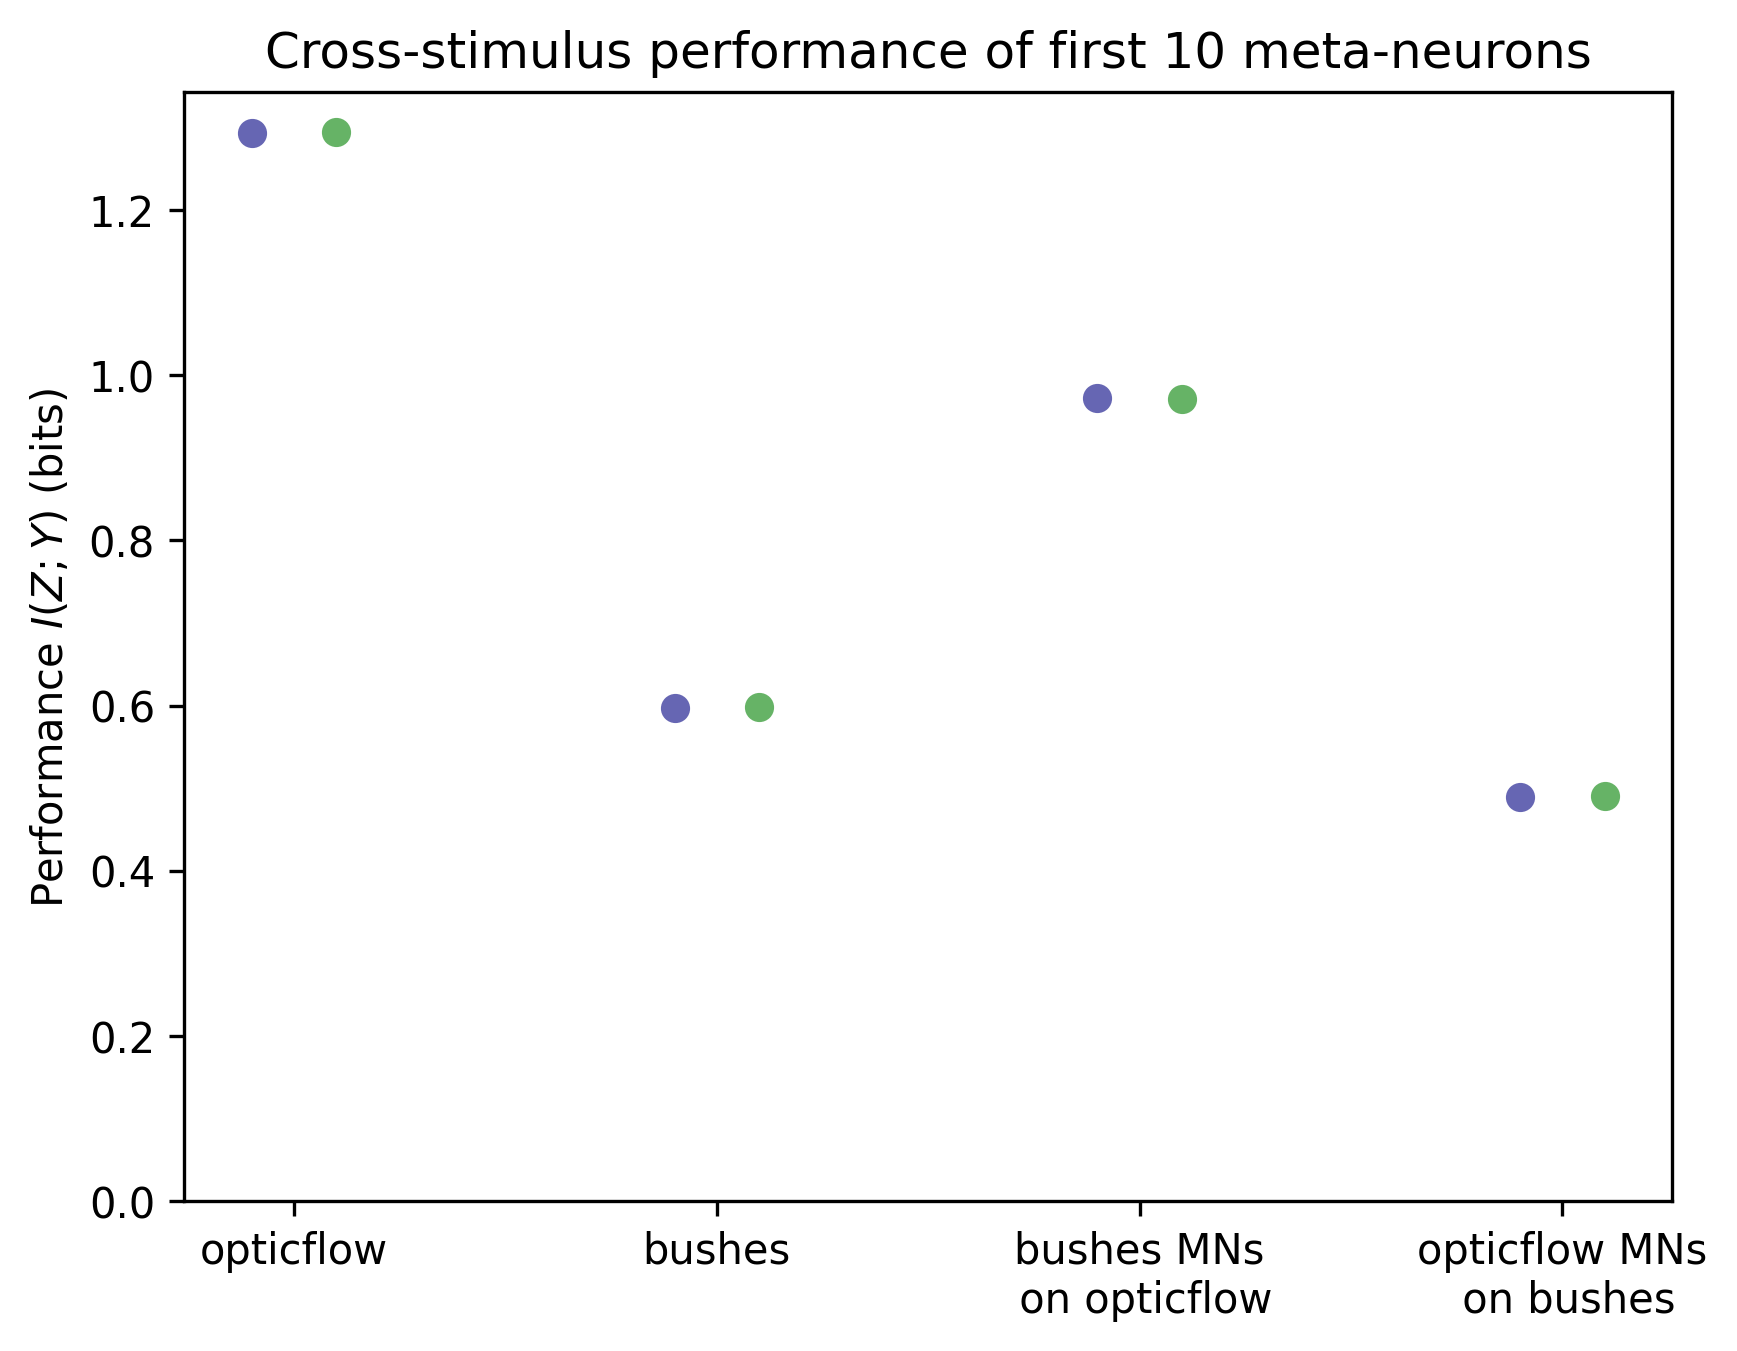

In [28]:
c1 = 0.4
c2 = 0.7
c3 = 0.9
alp1 = 0.4
alp2 = 0.9

plt.figure(dpi=300)
ls = 0.1
plt.errorbar(0-ls, mi_average_test_1 / np.log(2), mi_stdevs_test_1 / np.log(2), marker='o', color=(c1,c1,c2))
plt.errorbar(0+ls, mi_average_train_1 / np.log(2), mi_stdevs_train_1 / np.log(2), marker='o', color=(c1,c2,c1))

plt.errorbar(1-ls, mi_average_test_2 / np.log(2), mi_stdevs_test_2 / np.log(2), marker='o', color=(c1,c1,c2))
plt.errorbar(1+ls, mi_average_train_2 / np.log(2), mi_stdevs_train_2 / np.log(2), marker='o', color=(c1,c2,c1))

plt.errorbar(2-ls, mi_average_cross_test_2 / np.log(2), mi_stdevs_cross_test_2 / np.log(2), marker='o', color=(c1,c1,c2))
plt.errorbar(2+ls, mi_average_cross_train_2 / np.log(2), mi_stdevs_cross_train_2 / np.log(2), marker='o', color=(c1,c2,c1))

plt.errorbar(3-ls, mi_average_cross_test_1 / np.log(2), mi_stdevs_cross_test_1 / np.log(2), marker='o', color=(c1,c1,c2))
plt.errorbar(3+ls, mi_average_cross_train_1 / np.log(2), mi_stdevs_cross_train_1 / np.log(2), marker='o', color=(c1,c2,c1))


stim_name_1 = stim_names[stim_1]
stim_name_2 = stim_names[stim_2]
ax = plt.gca()
ax.set_xticks([0,1,2,3])
ax.set_xticklabels([
    f'{stim_name_1}',
    f'{stim_name_2}',
    f'{stim_name_2} MNs\n on {stim_name_1}',
    f'{stim_name_1} MNs\n on {stim_name_2}',
]);
ax.set_ylim(0)
ax.set_ylabel("Performance $I(Z;Y)$ (bits)")
ax.set_title(f"Cross-stimulus performance of first {N_meta_neurons} meta-neurons")